### 1. Import Necessary Libraries 

In [3]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### 2. Import Dataset

In [4]:
cars_data = pd.read_csv(filepath_or_buffer='Cars.csv')
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


### 3. Data Understanding

In [5]:
cars_data.shape

(81, 5)

In [6]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [7]:
cars_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [8]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


### Now,  let's check for the ASSUMPTIONS 

### Test 1 : Linearity Test

Do the linear test (graph) for all input features (X) against (Y)

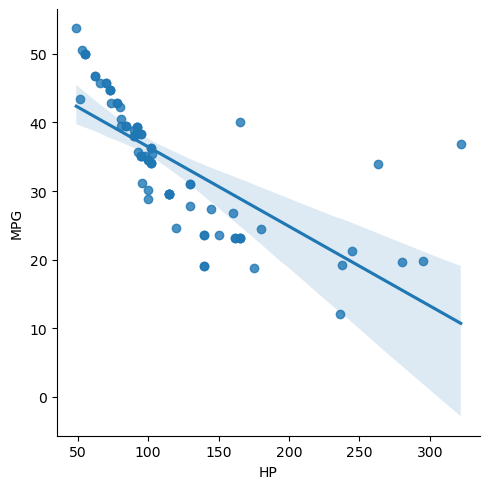

In [9]:
sns.lmplot(data=cars_data, x='HP', y='MPG')
plt.show()

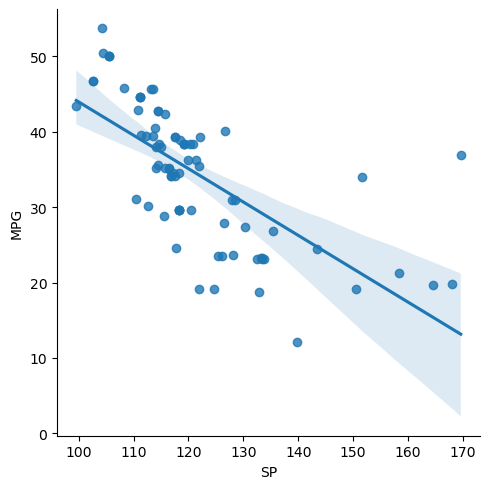

In [10]:
sns.lmplot(data=cars_data, x='SP', y='MPG')
plt.show()

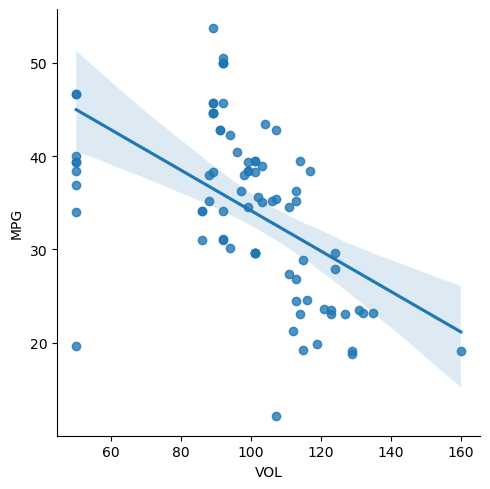

In [11]:
sns.lmplot(data=cars_data, x='VOL', y='MPG')
plt.show()

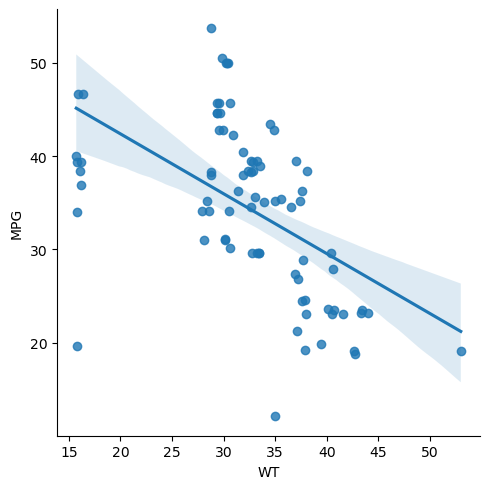

In [12]:
sns.lmplot(data=cars_data, x='WT', y='MPG')
plt.show()

Test 1 - Linearity test Failed !

### Test 2 : Normality Test

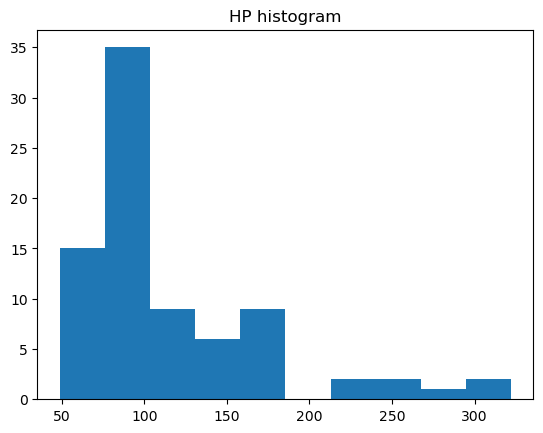

In [13]:
plt.hist(cars_data['HP'])
plt.title('HP histogram')
plt.show()

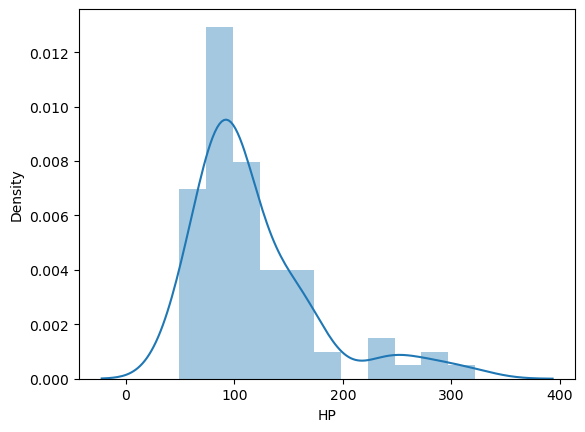

In [14]:
import warnings
warnings.filterwarnings(action='ignore')


sns.distplot(cars_data['HP'])
plt.show()

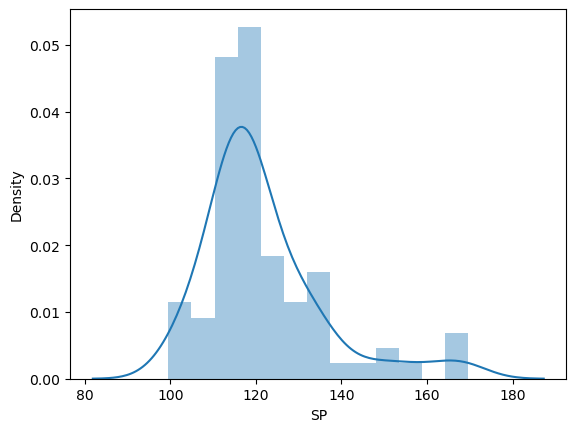

In [15]:
sns.distplot(cars_data['SP'])
plt.show()

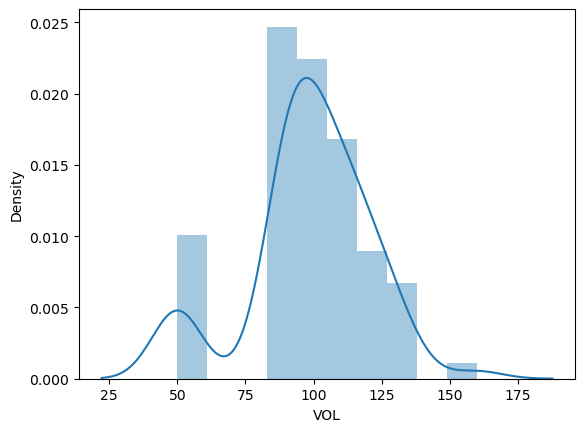

In [16]:
sns.distplot(cars_data['VOL'])
plt.show()

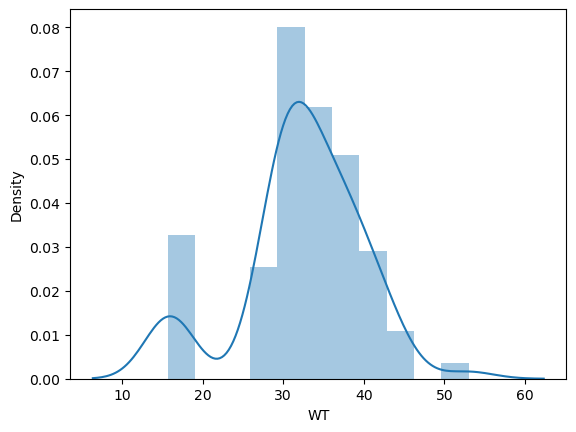

In [17]:
sns.distplot(cars_data['WT'])
plt.show()

Test 2 : Normality test Failed !

### Test 3 : Multi-colinearity

In [18]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


<Axes: >

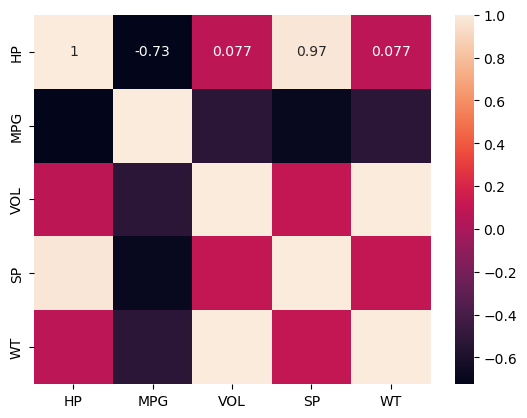

In [19]:
sns.heatmap(corr_matrix, annot=True)

There is Multi-colinearity --> becasue high correlation in (HP & SP) also (VOL & WT)

Test 3 : Failed

### Test 4 : Auto Regression Test
- Test - Passed , Because no time series data

### 4. Data Preparation

In [20]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [21]:
## x / y - Seperation

X = cars_data[['HP', 'VOL', 'SP', 'WT']]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [22]:
y = cars_data['MPG']
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

### 5. Model Building

In [26]:
# Train / Test data split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True, random_state=32)
X_train, X_test, y_train, y_test

(     HP  VOL          SP         WT
 45  100   99  117.105055  32.621916
 14   66   89  108.185353  29.347279
 23   81   96  113.829145  31.837122
 25   92   50  114.598513  16.043175
 69  245  112  158.300669  37.141733
 ..  ...  ...         ...        ...
 19   90  103  118.472936  33.516974
 62  140  131  126.048103  43.390988
 54  160  113  135.392639  37.254392
 5    70   89  113.185353  29.591768
 43   95   88  114.093383  28.343976
 
 [64 rows x 4 columns],
      HP  VOL          SP         WT
 21   74  107  110.840817  34.908211
 49  115  101  118.288996  33.458472
 8    62   50  102.598513  16.359484
 12   92   99  122.105055  32.813592
 28   52  104   99.564907  34.483207
 33  102  113  121.392639  37.573290
 7    62   50  102.598513  15.847758
 1    55   92  105.461264  30.466833
 58  100   94  112.645204  30.615283
 48  130   86  127.909442  28.070597
 60  145  111  130.208698  36.888153
 70  280   50  164.598513  15.823060
 56   96   92  110.461264  30.147543
 15   73   8

In [ ]:
# Train / Test split - without seperating X & Y - for OLS (ordinary least Square) model - during model evaluation
# OLS model will take formula during model training - does not requre seperating X & Y

cars_data_train, cars_data_test = train_test_split(cars_data, train_size=0.8, shuffle=True, random_state=32)

In [28]:
linear_model = LinearRegression()

linear_model

LinearRegression()

### 6. Model Training

In [29]:
linear_model.fit(X_train , y_train)

LinearRegression()

In [30]:
# Deliverable :
# intercept value - c
linear_model.intercept_

17.050354858798194

In [31]:
# Slope / coefficient - m
linear_model.coef_

array([-0.2277853 ,  0.10443408,  0.54523332, -0.99402148])

### 7. Model Testing

In [33]:
y_pred_train = linear_model.predict(X_train)

y_pred_test = linear_model.predict(X_test)

y_pred_train, y_pred_test

(array([36.03349187, 41.12559158, 39.04207624, 47.85147866, 22.33069231,
        38.73436173, 36.65226465, 25.85089994, 33.50397491, 15.97367055,
        49.33713444, 38.13891307, 17.18786626, 41.61801   , 41.39409211,
        24.76742351, 19.25035232, 34.03491922, 25.85339694, 24.29039634,
        25.45956959, 38.82727365, 25.35945716, 41.78534898, 36.00204172,
        34.77312721, 23.43290405, 34.87657343, 41.50381383, 28.63671811,
        43.39872972, 35.28170756, 29.29667161, 32.66118036, 35.85776172,
        36.32028984, 29.3457398 , 20.5794244 , 41.13582346, 38.08117407,
        31.86024078, 14.66285604, 33.35917528, 28.35322405, 39.36529704,
        32.88260582, 39.24172986, 41.15082809, 37.12306629, 41.07955447,
        37.7727425 , 37.31991977, 38.0942934 , 22.71290974, 49.77508725,
        41.83097505, 40.96265562, 42.12720146, 23.24057226, 38.58518835,
        24.43532879, 29.19467032, 42.69758938, 38.63394337]),
 array([37.10328425, 32.6395501 , 47.82782017, 40.39141028, 36

### 8. Model Evaluation

#### Training Data Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
import statsmodels.formula.api as smf

In [57]:
print('MAE :',mean_absolute_error(y_true=y_train, y_pred=y_pred_train), '# same unit')
print('MSE :',mean_squared_error(y_true=y_train, y_pred=y_pred_train), '# squared output unit')
print('R2 :',r2_score(y_true=y_train, y_pred=y_pred_train), '# normalised MSE unit')


MAE : 3.1091427234976132 # same unit
MSE : 17.75375609207912 # squared output unit
R2 : 0.7905236323200335 # normalised MSE unit


In [ ]:
# using statsmodel
# ordinary least square - used similarly with Linear Regressing line fitting
# using the cars training data 

linear_stats_model = smf.ols(formula='MPG ~ HP+VOL+SP+WT',data=cars_data_train).fit()

In [84]:
print("R2 score:", linear_stats_model.rsquared)
print("Adjusted R2 score:", linear_stats_model.rsquared_adj)

R2 score: 0.7905236323200332
Adjusted R2 score: 0.7763218446807134


#### Testing Data Evaluation

In [55]:
print('MAE :',mean_absolute_error(y_true=y_test, y_pred=y_pred_test))
print('MSE :',mean_squared_error(y_true=y_test, y_pred=y_pred_test))
print('R2 :',r2_score(y_true=y_test, y_pred=y_pred_test))

r2_score()


MAE : 4.333536315609443
MSE : 29.23820115624446
R2 : 0.5770101929490703


In [ ]:
# using statsmodel
# ordinary least square - used similarly with Linear Regressing line fitting

# ALREADY TRAINED using TRAIN DATA

In [86]:
# --- Evaluate on TEST Data ---

# Step A: Use the trained model to predict on the test dataframe
# (Statsmodels automatically extracts HP, VOL, SP, WT from cars_data_test)
y_pred_test_lsm = linear_stats_model.predict(cars_data_test)

# Step B: Pull out the actual target column from your test dataframe
y_test_lsm = cars_data_test['MPG']

# Step C: Compute Test R² using scikit-learn
r2_test = r2_score(y_true=y_test_lsm, y_pred=y_pred_test_lsm)

# Step D: Compute Test Adjusted R² using the formula
n_test = len(cars_data_test)
p = 4  # Number of predictors (HP, VOL, SP, WT)
adj_r2_test = 1 - ((1 - r2_test) * (n_test - 1) / (n_test - p - 1))

print(f"Test R²  : {r2_test:.4f}")
print(f"Test Adj R² : {adj_r2_test:.4f}")

Test R²  : 0.5770
Test Adj R² : 0.4360


In [ ]:
# using manual method - There are many auto method (MSE , MAE , Rsquared, ...)
# using all the data - old method - before train / test split

y_pred = linear_model.predict(X)
error = y - y_pred
error

0     10.301952
1      8.666994
2      8.395391
3      3.569121
4      8.673257
        ...    
76    11.540543
77    -0.052465
78     4.654260
79     5.170877
80    -3.872408
Name: MPG, Length: 81, dtype: float64

### Test 5 : Homoscedasticity Test

Text(0.5, 0, 'x')

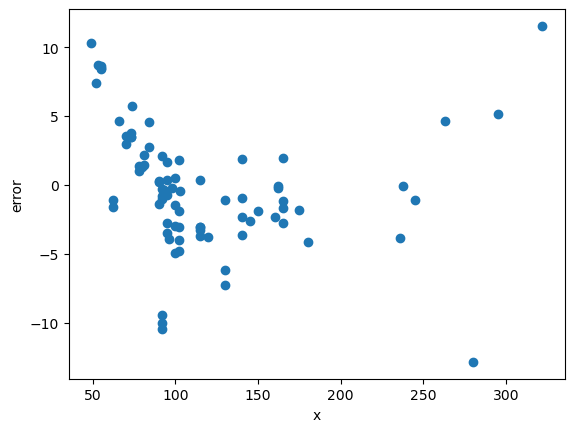

In [40]:
# using plt
plt.scatter(x=cars_data['HP'], y=error)
plt.ylabel('error')
plt.xlabel('x')

Text(0.5, 0, 'x')

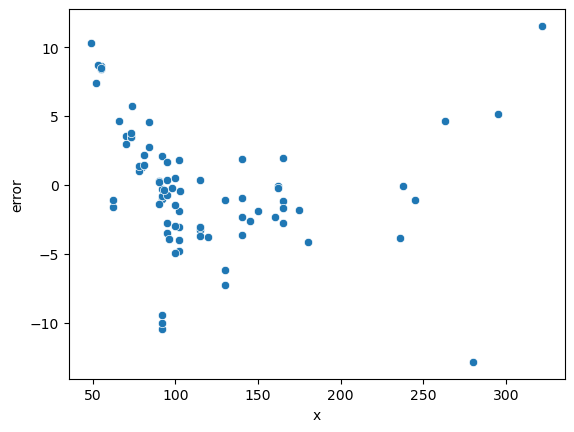

In [41]:
# using sns
sns.scatterplot(data=cars_data ,x=cars_data['HP'], y=error)
plt.ylabel('error')
plt.xlabel('x')

Text(0.5, 0, 'x')

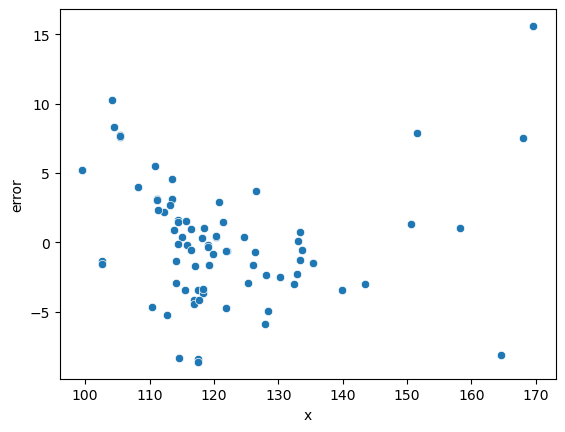

In [42]:
sns.scatterplot(data=cars_data ,x=cars_data['SP'], y=error)
plt.ylabel('error')
plt.xlabel('x')

Text(0.5, 0, 'x')

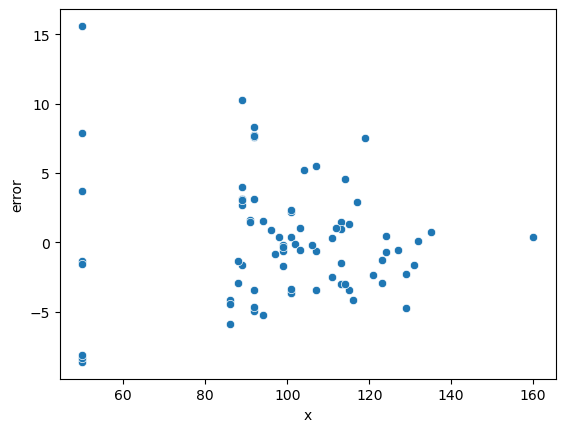

In [40]:
sns.scatterplot(data=cars_data ,x=cars_data['VOL'], y=error)
plt.ylabel('error')
plt.xlabel('x')

Text(0.5, 0, 'x')

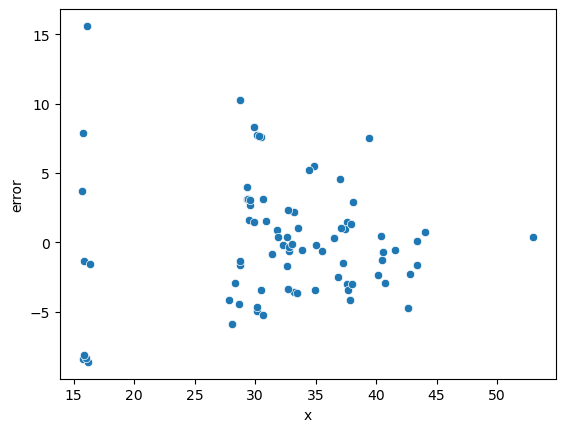

In [41]:
sns.scatterplot(data=cars_data ,x=cars_data['WT'], y=error)
plt.ylabel('error')
plt.xlabel('x')

Test 5 : Homoscedasticity test also Failed

### Test 6 : Zero Residual Mean Test

<Axes: xlabel='MPG'>

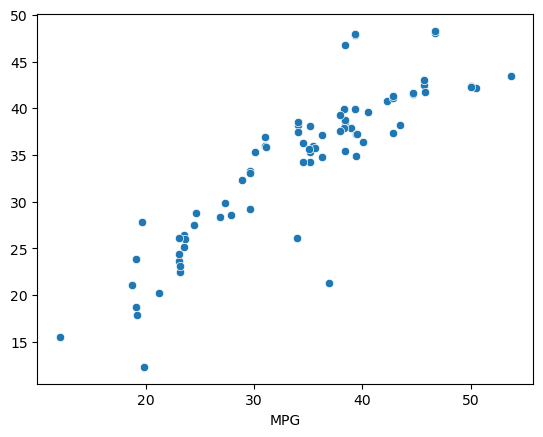

In [44]:
# Zero Residual Mean - compares actual output & predicted output

sns.scatterplot(x=y, y=y_pred)

### 9. Model Deployment

In [45]:
from pickle import dump , load

# exporting the Intelligence File

dump(obj=linear_model, file=open(file='linear_intelligence_file.pkl', mode='wb'))

In [46]:
# loading the intelligence file

linear_intel_pk = load(file=open(file='linear_intelligence_file.pkl', mode='rb'))
linear_intel_pk

LinearRegression()

In [48]:
linear_intel_pk.predict(X)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

### THE END